# CS110 Into the Package-Verse Plotting
### Reading CSV files and plotting weather data with Matplotlib

**Name:** ______________________________

In this notebook, you will practice using Python to read data from files and create plots that communicate information clearly. The weather data describe daily high and low temperatures in Death Valley, California.

**By the end, you should be able to:**
- Read a `.csv` file using `csv.DictReader()`.
- Make and customize a plot with `matplotlib.pyplot`.
- Compare data across dates and across years.
- Develop **three possible research questions** for your final project.

**Directions:** Run the setup and lecture example first. Then **complete at least one of the three plotting activities**. If you finish early, try a second or third. Complete the project brainstorm and review your plots before you finish. Run cells from top to bottom whenever you restart the Colab runtime.

> **Google Colab tip:** Select **File → Save a copy in Drive** if you want your own editable copy. The CSV files are downloaded automatically; you do not need to mount Google Drive.

---
## 1. Get the weather data from GitHub

Run the next code cell to download the three CSV files into your Colab workspace. You do not need to upload files or connect Google Drive.

| CSV file | What we will use it for |
|---|---|
| `death_valley_2021_simple.csv` | First plot and styling practice |
| `death_valley_2021_full.csv` | Plot daily temperatures across an entire year |
| `death_valley_2018_full.csv` | Compare maximum temperatures in 2018 and 2021 |


In [17]:

from urllib.request import urlretrieve

# GitHub repository containing the data
base_url = "https://raw.githubusercontent.com/lopezbec/intro_python_notebooks/main/"

# Download the CSV files
files = [
    "death_valley_2021_simple.csv",
    "death_valley_2021_full.csv",
    "death_valley_2018_full.csv"
]

for filename in files:
    urlretrieve(base_url + filename, filename)
    print("Downloaded:", filename)

# File paths used throughout the worksheet
simple_path = "death_valley_2021_simple.csv"
full_2021_path = "death_valley_2021_full.csv"
full_2018_path = "death_valley_2018_full.csv"


Downloaded: death_valley_2021_simple.csv
Downloaded: death_valley_2021_full.csv
Downloaded: death_valley_2018_full.csv


---
## 2. A quick review: read a CSV file

A **CSV** (comma-separated values) file stores data in rows and columns. The first row usually contains **column names**.

The `csv` module is part of Python's standard library. Its `csv.DictReader()` function reads each row as a **dictionary**, so you can use `row["DATE"]` or `row["TMAX"]` instead of remembering column numbers.

For this worksheet:
- `DATE` = the date of the measurement
- `TMAX` = daily maximum temperature, in °F
- `TMIN` = daily minimum temperature, in °F

Some full-year rows have **missing values**, so the plotting code should skip those rows when necessary.

In [18]:
import csv

# Explore the file: show its headers and the first three records.
with open(simple_path, newline="", encoding="utf-8-sig") as data_file:
    reader = csv.DictReader(data_file)
    print("Columns:", reader.fieldnames)
    print("\nFirst three records:")
    for index, row in enumerate(reader):
        if index == 3:
            break
        print("Date:", row["DATE"],  "| High:", row["TMAX"], "| Low:", row["TMIN"])

Columns: ['STATION', 'NAME', 'DATE', 'TMAX', 'TMIN', 'TOBS']

First three records:
Date: 1/1/2021 | High: 71 | Low: 51
Date: 1/2/2021 | High: 67 | Low: 42
Date: 1/3/2021 | High: 66 | Low: 41


### Dates and missing values

A date read from a CSV file begins as a **string**. We can turn it into a Python date with `datetime.strptime()`. Different CSV files may write the date in different formats (for example, `2021-01-16` or `1/16/2021`).

The function below recognizes both formats. You can reuse it in the activities.

In [19]:
from datetime import datetime


def parse_weather_date(date_text):
    # Try the two common date formats in these weather files.
    for date_format in ("%Y-%m-%d", "%m/%d/%Y"):
        try:
            return datetime.strptime(date_text.strip(), date_format)
        except ValueError:
            pass
    raise ValueError("Date format not recognized: " + date_text)

print(parse_weather_date("2021-01-16"))
print(parse_weather_date("1/16/2021"))

2021-01-16 00:00:00
2021-01-16 00:00:00


---
## 3. Matplotlib quick reference

`matplotlib.pyplot` (usually named **`plt`**) contains functions for making graphs.

| Syntax | What it does |
|---|---|
| `plt.plot(x, y)` | Draw a line plot |
| `plt.plot(x, y, "o")` | Plot points using circle markers |
| `plt.bar(x, y)` | Draw a bar chart |
| `plt.title("...")` | Add a descriptive title |
| `plt.xlabel("...")` | Label the x-axis |
| `plt.ylabel("...")` | Label the y-axis (include units!) |
| `plt.grid()` | Add gridlines |
| `plt.legend()` | Display labels provided with `label=` |
| `plt.xticks(rotation=45)` | Rotate tick labels to improve readability |
| `plt.show()` | Display the figure |

You can also change line **colors**, **markers**, and **line styles**. For example:

```python
plt.plot(x, y, color="green", marker="o", linestyle="--", label="High")
```

See [Matplotlib markers](https://matplotlib.org/stable/api/markers_api.html) for more options.

**Good plots tell a story:** choose a suitable chart type, use meaningful labels, include temperature units (°F), and make the figure easy to interpret.

---
## 4.  Example: maximum and minimum temperature

This starting point uses the same approach as the lecture demonstration:

1. Create empty lists for dates, maximum temperatures, and minimum temperatures.
2. Read the CSV with `csv.DictReader()` and append values to the lists.
3. Make two lines and add the title, axes, grid, and legend.

Run the cell. Notice how the plotted lines correspond to the columns in the CSV file.

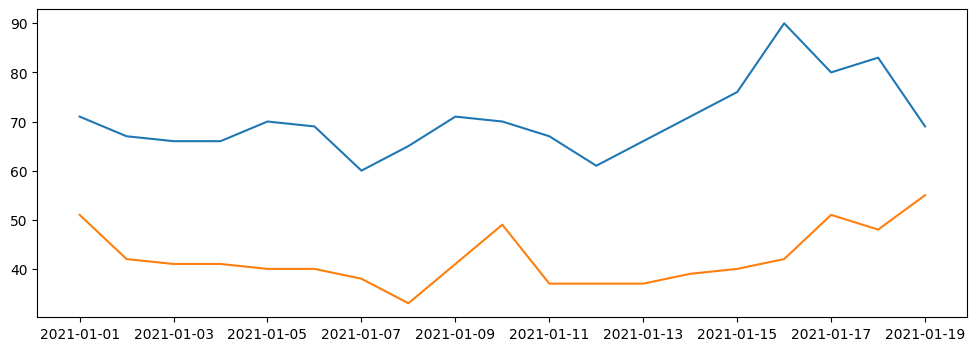

In [20]:
import csv
import matplotlib.pyplot as plt

# Create lists for the three columns we want to plot.
demo_dates = []
demo_tmax = []
demo_tmin = []

with open(simple_path) as myfile:
    mycsv = csv.DictReader(myfile)
    for row in mycsv:
        # Skip rows without both temperature measurements.
        if row["TMAX"] == "" or row["TMIN"] == "":
            continue
        demo_dates.append(parse_weather_date(row["DATE"]))
        demo_tmax.append(int(row["TMAX"]))
        demo_tmin.append(int(row["TMIN"]))

# Draw the two series using Matplotlib.
plt.figure(figsize=(12, 4))
plt.plot(demo_dates, demo_tmax)
plt.plot(demo_dates, demo_tmin)
plt.show()


---
## 5. Plotting activities — choose at least one

All three activities use the CSV files downloaded in Section 1. You may reuse ideas from the lecture example, but the completed plot should clearly communicate the information it displays.

### Activity A — Customize the first plot

Use `death_valley_2021_simple.csv` and plot **TMAX and TMIN over time**. Make at least **three useful design choices**. For example, you could change colors or markers, add a title, adjust the legend, add a grid, or improve date labels.

**Before coding:** What would make the two temperature measurements easiest to compare?

In [21]:
# Activity A — Customize the TMAX/TMIN plot.
# You can keep the lecture example as a starting point and make it your own.

style_dates = []
style_tmax = []
style_tmin = []


### Activity B — Plot an entire year

Open `death_valley_2021_full.csv` and plot the **daily TMAX and TMIN values across 2021**.

**Think about:**
- Which column names contain the information you need?
- How will you handle rows that have no temperature value?
- What figure size and tick labels make a full year readable?

Include a title, labeled axes (with units), and a legend. **Hint:** A full year usually benefits from fewer tick labels than a short sample.

In [22]:
# Activity B — Plot maximum and minimum temperatures for the full year 2021.
year_2021_dates = []
year_2021_tmax = []
year_2021_tmin = []



### Activity C — Compare 2018 with 2021

Read `death_valley_2018_full.csv` and `death_valley_2021_full.csv`. Visualize the difference in **daily maximum temperature** between the two years.

Because the observations come from different years, a useful approach is to place them on the same **day-of-year axis** (January = beginning of the graph, December = end). Another visualization is acceptable if it communicates the comparison clearly.

**Think about:**
- How can you identify the corresponding time of year across the two datasets?
- What happens when a row is missing its TMAX measurement?
- Which parts of the year appear to show the largest differences?

In [23]:
# Activity C — Compare TMAX values for 2018 and 2021 on the same day-of-year axis.
comparison_2018_days = []
comparison_2018_max = []
comparison_2021_days = []
comparison_2021_max = []



### Interpret your visualization

After completing a plot, write **2–3 sentences** explaining what the graph shows. Include an observation supported by the data and explain one design choice you made.

**My observation:**

*Write here.*

**Why I chose this plot or style:**

*Write here.*

---
## 6. Final project brainstorm — three possible directions

For your **Final Project: Visualizing Data with Python**, you will investigate a guiding question using a real, publicly available dataset and meaningful visualizations.

Develop **three different possible topics** that interest you. For each idea, identify:
1. A **general category** and a **specific research question**.
2. The **data/variables** you would need.
3. Why the question interests you.
4. A **possible public data source** (include a link when you find one).

Choose questions that could be explored by **reading data files** and **creating plots**, rather than questions that can be answered with only one number. You do not need to finalize your project today.

### Project idea 1 — Climate and weather

- **Research question:** How has the number of unusually hot days changed over time in a selected U.S. city?
- **Variables:** Daily maximum temperature, date, location, year, and a chosen high-temperature threshold.
- **Why it interests me:** I want to explore whether very hot days are becoming more common and whether that pattern differs by location.
- **Possible data source:** [NOAA Climate Data](https://www.ncei.noaa.gov/cdo-web/datasets).

### Project idea 2 — Education

- **Research question:** How has undergraduate enrollment changed over time at different types of U.S. institutions?
- **Variables:** Enrollment, year, institution type, and perhaps location.
- **Why it interests me:** Enrollment trends may reveal differences between institution categories and changes over time.
- **Possible data source:** [U.S. Department of Education Data](https://nces.ed.gov/ipeds/use-the-data).

### Project idea 3 — Employment

- **Research question:** How do unemployment rates change across states over time?
- **Variables:** Unemployment rate, state, date/year, and optionally labor force participation.
- **Why it interests me:** I want to see whether states experience similar employment trends or show different patterns.
- **Possible data source:** [Bureau of Labor Statistics](https://www.bls.gov/data/).

**My preferred idea so far:** Climate and weather, because it could support both a time-series plot and a comparison between locations.

---
## 7. Before you finish

- [ ] I completed **at least one** plotting activity.
- [ ] My graph has a clear title, labeled axes, and the correct units.
- [ ] I can explain one pattern visible in my graph.
- [ ] I have three possible final-project questions, the variables I would need, and potential data sources.

**Save your notebook** after making your changes, and follow the submission instructions provided in Moodle.